<a href="https://colab.research.google.com/github/Maitebeleen/proyecto-opti/blob/main/Copia_de_Proyecto_Optimizaci%C3%B3n_Arredondo_Bascu%C3%B1%C3%A1n_Eyheramendy_Moreno_Rocha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto de Optimización**

**Optimización, Sección 2**

**Alumnos:**
*   Francisco Arredondo
*   Francisca Bascuñán
*   Sofía Eyheramendy
*   Maite Moreno
*   Fernanda Rocha

**Profesora:** \
Viviana Barile

**Fecha:** \
15 de Noviembre del 2026




# Códigos

***Códigos que se tienen que correr para que funcione el colab***

In [ ]:
!pip install -q gurobipy
from google.colab import drive
drive.mount('/content/drive')
import os
os.environ['GRB_LICENSE_FILE'] = '/content/drive/MyDrive/gurobi.lic'
import gurobipy as gp
gp.Model()

Mounted at /content/drive
Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2884705
Academic license 2884705 - for non-commercial use only - registered to fr___@alumnos.uai.cl


<gurobi.Model Continuous instance Unnamed: 0 constrs, 0 vars, Parameter changes: LicenseID=2884705>

In [ ]:
# =============================================================================
# DATOS DEL PROYECTO 2026-2: FIESTA DE VERANO DE VILLA PEUMAYÉN
# ING200: Optimización
#
# Este archivo contiene los datos del proyecto y dos funciones de apoyo:
#   - demanda(artistas): estima el público que convoca un conjunto de artistas.
#   - mostrar_parrilla(parrilla): muestra una parrilla y su público por noche.
# Puede copiar todo su contenido directamente en su script.
#
# Los montos están en millones de pesos (MM$).
# =============================================================================

# -----------------------------------------------------------------------------
# NOCHES DEL FESTIVAL
# FACTOR_NOCHE[n]: fracción de la demanda que asiste la noche n.
# -----------------------------------------------------------------------------
NOCHES = ['Viernes', 'Sábado', 'Domingo']
FACTOR_NOCHE = {'Viernes': 0.90, 'Sábado': 1.00, 'Domingo': 0.85}

# -----------------------------------------------------------------------------
# RECINTOS
# recinto: capacidad (personas) y costo de arriendo por noche (MM$).
# Todos los recintos están disponibles las tres noches.
# -----------------------------------------------------------------------------
RECINTOS = {
    'Plaza de Armas':     {'capacidad': 12000, 'costo': 30},
    'Medialuna':          {'capacidad': 7500,  'costo': 18},
    'Gimnasio Municipal': {'capacidad': 4200,  'costo': 8},
}

# -----------------------------------------------------------------------------
# ARTISTAS
# nombre: género, nivel ('G' grande, 'M' mediano, 'P' pequeño),
#         popularidad (índice individual), costo (MM$) y noches disponibles.
# -----------------------------------------------------------------------------
ARTISTAS = {
    'La Sonora Copihue':           {'genero': 'Cumbia',  'nivel': 'G', 'popularidad': 1.08, 'costo': 52, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Los Volcanes':                {'genero': 'Rock',    'nivel': 'G', 'popularidad': 0.97, 'costo': 40, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Camila Arrebol':              {'genero': 'Pop',     'nivel': 'G', 'popularidad': 1.03, 'costo': 48, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Kevo Flow':                   {'genero': 'Urbano',  'nivel': 'G', 'popularidad': 1.12, 'costo': 58, 'noches': ['Viernes', 'Sábado']},
    'Los Cumbiancheros del Ñuble': {'genero': 'Cumbia',  'nivel': 'M', 'popularidad': 0.94, 'costo': 18, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Grupo Tierra Sur':            {'genero': 'Folclor', 'nivel': 'M', 'popularidad': 1.06, 'costo': 15, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'La Nena Real':                {'genero': 'Urbano',  'nivel': 'M', 'popularidad': 1.01, 'costo': 22, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Las Hermanas Quintral':       {'genero': 'Pop',     'nivel': 'M', 'popularidad': 0.92, 'costo': 17, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Ruta Cinco':                  {'genero': 'Rock',    'nivel': 'M', 'popularidad': 1.04, 'costo': 16, 'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Banda Fogata':                {'genero': 'Cumbia',  'nivel': 'P', 'popularidad': 1.11, 'costo': 7,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Conjunto Raíces del Valle':   {'genero': 'Folclor', 'nivel': 'P', 'popularidad': 0.98, 'costo': 5,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Las Cantoras de Peumayén':    {'genero': 'Folclor', 'nivel': 'P', 'popularidad': 0.89, 'costo': 4,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Niebla Austral':              {'genero': 'Rock',    'nivel': 'P', 'popularidad': 0.95, 'costo': 6,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Tomás del Lago':              {'genero': 'Pop',     'nivel': 'P', 'popularidad': 1.09, 'costo': 8,  'noches': ['Viernes', 'Sábado', 'Domingo']},
    'Yisus Beat':                  {'genero': 'Urbano',  'nivel': 'P', 'popularidad': 0.91, 'costo': 6,  'noches': ['Viernes', 'Sábado', 'Domingo']},
}

# -----------------------------------------------------------------------------
# REGLAS ENTRE ARTISTAS
# TELONEROS: si se contrata al primero, el segundo debe presentarse la misma noche.
# EXCLUSIONES: no pueden ser contratados ambos.
# -----------------------------------------------------------------------------
TELONEROS = [('La Sonora Copihue', 'Banda Fogata')]
EXCLUSIONES = [('La Nena Real', 'Yisus Beat')]

# -----------------------------------------------------------------------------
# PARÁMETROS GENERALES
# -----------------------------------------------------------------------------
PRESUPUESTO = 250              # MM$: artistas + arriendo de recintos + plan de seguridad
UMBRAL_SEGURIDAD = 20000       # personas: si el público total del festival lo supera, se exige el plan
COSTO_SEGURIDAD = 25           # MM$

# -----------------------------------------------------------------------------
# PARÁMETROS DE LA FUNCIÓN DE DEMANDA (usados por la función demanda)
# -----------------------------------------------------------------------------
BASE_NIVEL = {'G': 4200, 'M': 1900, 'P': 750}
FACTOR_GENERO = {'Cumbia': 1.20, 'Urbano': 1.10, 'Pop': 1.00, 'Rock': 0.95, 'Folclor': 0.65}
ARRASTRE = 0.20                # aumento de la base de artistas M y P si en la noche hay un artista G
MISMO_GENERO = -0.15           # por cada par de artistas del mismo género
DOS_GRANDES = -0.10            # por cada par de artistas grandes
AFINIDAD = {('Cumbia', 'Urbano'): 0.06, ('Pop', 'Rock'): 0.05, ('Pop', 'Urbano'): 0.03}


def demanda(artistas):
    """Demanda esperada (personas) de un conjunto de artistas que se presentan la misma noche.

    No considera la noche ni el recinto: el público esperado de la noche n en el recinto r es
        min(FACTOR_NOCHE[n] * demanda(artistas), capacidad del recinto r),
    redondeado al entero más cercano.

    Ejemplo: demanda(['Kevo Flow', 'Ruta Cinco', 'Banda Fogata'])
    También acepta conjuntos de uno o dos artistas (útil, por ejemplo, para analizar cancelaciones).
    """
    artistas = list(artistas)
    hay_grande = any(ARTISTAS[a]['nivel'] == 'G' for a in artistas)
    base = 0.0
    for a in artistas:
        datos = ARTISTAS[a]
        b = BASE_NIVEL[datos['nivel']] * FACTOR_GENERO[datos['genero']] * datos['popularidad']
        if hay_grande and datos['nivel'] != 'G':
            b *= 1 + ARRASTRE
        base += b
    interaccion = 0.0
    for i in range(len(artistas)):
        for j in range(i + 1, len(artistas)):
            a1, a2 = ARTISTAS[artistas[i]], ARTISTAS[artistas[j]]
            if a1['genero'] == a2['genero']:
                interaccion += MISMO_GENERO
            interaccion += AFINIDAD.get((a1['genero'], a2['genero']), AFINIDAD.get((a2['genero'], a1['genero']), 0))
            if a1['nivel'] == 'G' and a2['nivel'] == 'G':
                interaccion += DOS_GRANDES
    return base * (1 + interaccion)


def mostrar_parrilla(parrilla, titulo='Parrilla del festival'):
    """Muestra una parrilla con su público y su costo por noche.

    parrilla: lista de tuplas (noche, recinto, [artista1, artista2, artista3]), por ejemplo
        [('Viernes', 'Medialuna', ['Kevo Flow', 'Ruta Cinco', 'Banda Fogata']), ...]
    El costo mostrado incluye artistas y recinto, pero no el plan de seguridad.
    """
    import matplotlib.pyplot as plt
    orden = {n: i for i, n in enumerate(NOCHES)}
    parrilla = sorted(parrilla, key=lambda t: orden[t[0]])
    print(f'{titulo}\n' + '-' * 100)
    total_pub, total_costo, publicos = 0, 0, []
    for noche, recinto, artistas in parrilla:
        pub = round(min(FACTOR_NOCHE[noche] * demanda(artistas), RECINTOS[recinto]['capacidad']))
        costo = sum(ARTISTAS[a]['costo'] for a in artistas) + RECINTOS[recinto]['costo']
        total_pub += pub; total_costo += costo; publicos.append(pub)
        nombres = ', '.join(f"{a} ({ARTISTAS[a]['nivel']})" for a in artistas)
        print(f'{noche:8s} | {recinto:18s} | {pub:6,d} personas | {costo:4d} MM$ | {nombres}')
    print('-' * 100 + f'\nTotal: {total_pub:,} personas | {total_costo} MM$ (sin plan de seguridad)')
    plt.figure(figsize=(7, 3.5))
    barras = plt.bar([p[0] for p in parrilla], publicos, color=['#1565c0', '#c62828', '#2e7d32'][:len(parrilla)])
    for b, (noche, recinto, _) in zip(barras, parrilla):
        plt.text(b.get_x() + b.get_width() / 2, b.get_height(), recinto, ha='center', va='bottom', fontsize=9)
    plt.ylabel('Público esperado'); plt.title(titulo); plt.tight_layout(); plt.show()

# *Item a)*

***Pregunta:*** \
Formule un modelo de programación lineal entera que permita a la municipalidad decidir
qué tres artistas se presentan cada noche y en qué recinto, de modo de maximizar
el público total esperado respetando todas las condiciones descritas. Defina claramente
**conjuntos, parámetros y variables de decisión, y explique el significado de cada restricción**. \
Explique cómo incorpora la función de *demanda en su modelo* y por qué su *modelo es
lineal*, a pesar de que la demanda de una noche no es la suma de las demandas de cada
artista.

***Respuesta:***

***Formulación modelo:***

Para definir los **parámetros**, tenemos que considerar que, estos son datos que nos da el mismo enunciado, por ende no podemos decidir sobre ellos.

<br>

* $CostoA_a$: Costo en millones de pesos [MM\$] de contratar el artista $a$.

<br>

* $CostoR_r$: Costo en millones de pesos [MM\$] de arriendo del recinto $r$ por una noche.

<br>

* $$Disp_{a,n} = \begin{cases}
1 & \text{si el artista $a$ puede presentarse en la noche $n$ (según su disponibilidad)} \\
0 & \text{en otro caso}
\end{cases}$$

$$Disp_{a,n} \in \{0, 1\}$$

  **Acotación:* La disponibilidad de cada artista se encuentra en el código accediendo a este con la siguiente línea de código:
  \
  *ARTISTAS['NOMBRE ARTISTA']['noches']*.

<br>

* $D(c)$ : Demanda estimada de la combinación de artistas $c$ que se presentan en la misma noche, calculada a partir de la siguiente fórmula:
$$D(c) = \left( \sum_{a \in c} b_a \right) (1 + I).$$\
  con $b_a$: Demanda base del artista $a$, calculada a partir de la multiplicación de la base según su nivel, el factor de su género, su popularidad y un posible efecto arrastre.

  con $I$: Ajuste de interacción entre los artistas de la combinación $c$.

  <br>

* $P_{c,n,r}$ :  Público esperado de la combinación de artistas $c$ en la noche $n$ en el recinto $r$, calculada a partir de la siguiente fórmula (redondeado al entero más cercano): $$min(Ø_n \cdot D(c) \, ,\, K_r )$$

  con $Ø_n$: Factor de asistencia por noche.\
  con $K_r$: Capacidad del recinto.

  <br>

* $Presupuesto$ = 250 [MM\$]

<br>

* $Umbral$ $de$ $seguridad$ = 20 000\
  (si el público total supera este número, la municipalidad debe implementar un plan de seguridad)

  <br>

* $Costo$ $de$ $Seguridad$ = 25 [MM\$]

<br>

* $M$ : Big-M en caso que se requiera activar o desactivar una condición mediante una variable binaria; en este caso el plan de seguridad . \
**Acotación*:  Para el código, posteriormente se utilizará $M= 16 \ 000$, pues el el valor más ajustado según las capacidades posibles de los recintos.




Primeramente, definiremos los **conjuntos** requeridos:

* **$A$**:  Conjunto de todos los artistas candidatos $A= \{a_1,a_2, ... ,a_{15}\}$ = {"La Sonora Copihue", "Los volcanes",..., "Yisus Beat"}.

* **$N$**:  Conjunto de noches del festival $N$= {Viernes, Sábado, Domingo}.\
**Acotación:* Este conjunto para el código, al momento de programar, será la lista $NOCHES$.

* **$R$**:  Conjunto de recintos disponibles $R$= {Plaza de Armas, Medialuna, Gimnasio Municipal}.\
**Acotación:* Este conjunto para el código, al momento de programar, será la lista $RECINTOS$.

* **$C$**:  Conjunto de todas las combinaciones posibles de exactamente tres artistas distintos (para cada noche) pertenencientes a $A$, es decir, $C = \{c \subseteq A : |c| = 3\}$.


Para las **variables de decisión**, se consideran las opciones que permitiran resolver el problema a través del uso de Gurobi.

* $$X_{c,n,r} = \begin{cases}
1 & \text{si se asigna la combinación de artistas $c$ en la noche $n$ al recinto $r$} \\
0 & \text{en otro caso}
\end{cases}$$

$$X_{c,n,r} \in \{0, 1\}$$

<br>

* $$Y_{a} = \begin{cases}
1 & \text{si el artista $a$ es contratado para participar en el festival} \\
0 & \text{en otro caso}
\end{cases}$$

$$Y_{a} \in \{0, 1\}$$

<br>

* $$S = \begin{cases}
1 & \text{si se activa el plan de seguridad} \\
0 & \text{en otro caso}
\end{cases}$$

$$S \in \{0, 1\}$$


Considerando que el objetivo de la municipalidad es maximizar el público total esperado del festival, se definirá de la siguiente forma la *función objetivo* :

**Función objetivo**:

$$ \max \ z = \sum_{n \in N} \sum_{r \in R} \sum_{c \in C} P_{c,n,r} \cdot X_{c,n,r} $$

**Restricciones**:

1. Asignación única: Cada noche $n$ debe tener exactamente una combinación de artistas y un recinto asociado.\
$$ \sum_{r \in R} \sum_{c \in C} X_{c,n,r} =1 $$
<center> $\forall n \in N$</center>

 *Explicación de la restricción (1):*\
La restricción establece que, para cada noche del festival, se debe escoger solamente una combinación de tres artistas y un recinto. Para esto, se suman las variables binarias correspondientes a todas las combinaciones y recintos posibles para un día, y se exige que su resultado sea igual a $1$.

2. Un artista $a$ es contratado si alguna combinación de artistas que lo incluye efectivamente es elegida.

$$ Y_a= \sum_{n \in N} \sum_{r \in R} \sum_{c \in C: a \in c} \ X_{c,n,r} $$
<center> $∀ a \in A $<center>

 *Explicación de la restricción (2):*\
 Esta restricción relaciona la variable de contratación $Y_a$ con todas las combinaciones, seleccionadas mediante $X_{c,n,r}$. Así, un artista se considera contratado si es que pertenece a alguna combinación (con una noche y recinto asignado). Además, como $Y_a$ es una variable binaria, ya se limita que un mismo artista sea seleccionado más de una vez durante el festival.

3. Cada artista puede presentarse a lo más una vez en el festival:

$$Y_a \leq 1 \quad \forall a \in A$$

<center> restricción por implicancia lógica </center>

<br>


4. ... y solo en las noches que está disponible:
$$ \sum_{r \in R} \sum_{c \in C : a \in c} X_{c,n,r} \leq Disp_{a,n} \quad \forall a \in A, \forall n \in N $$


*Explicación de la restricción (4):*\
 Primeramente, se chequea $X_{c,n,r}$ para todo los recintos y todas las combinaciones que contienen el artista $a$, valiendo 1 si es que efectivamente se selecciona esta combinación para la noche $n$ en el recinto $r$. Esto tiene que ser igual o menor a la disponibilidad que tenga el artista, valiendo 1 si el artista $a$ efectivamente está disponible en la noche $n$. Se utiliza un $\leq$ , pues que esté disponible no significa que el artista tenga que presentarse realmente.

5. Si se contrata a  La Sonora Copihue, Banda Fogata debe presentarse la misma noche:

$$ \sum_{r \in R} \sum_{c \in C : a_1 \in c} X_{c,n,r} \leq \sum_{r \in R} \sum_{c \in C : a_{10} \in c} X_{c,n,r}$$
<center> $\forall n \in N$</center>
<center> $a_1$ : La Sonora Copihue</center>
<center> $a_{10}$ : Banda Fogata</center>

<br>

*Explicación de la restricción (5):*\
 Primeramente, se chequea $X_{c,n,r}$ para todos los recintos y todas las combinaciones que contienen al artista $a_1$, es decir, La Sonora Copihue. Luego, se repite el mismo procedimiento para $a_{10}$, es decir, Banda Fogata. Así, se condiciona que si se contrata a La Sonora Copihue, necesariamente se debe contratar a la Banda Fogata, sin embargo  esta es una implicancia en un solo sentido, pues no necesariamente se va a contratar a La Sonora Copihue si es que se contrata la Banda Fogata.



6. La Nena Real y Yisus Beat no aceptan participar en
el mismo festival:\
$$ Y_{a_7}+ Y_{a_{15}} \leq 1 $$
<center> $a_7$ : La Nena Real</center>
<center> $a_{15}$ : Yisus Beat</center>

*Explicación de la restricción (6):*\
 Dado que la Nena Real y Yisus Beat no pueden ser contratados simultáneamente para el festival, independiente de la noche que se presenten, se utiliza la variable $Y_a$ para saber si es que efectivamente fue contratado el artista para participar en el festival. Así, la suma de sus variables tiene que ser menor o igual a $1$ dado que, como posibilidades, puede ser contratado uno de los dos o ninguno.

Si el público total esperado del festival supera las 20 000 personas,
la municipalidad debe implementar un plan de seguridad:

7. Obliga a activar el plan si se supera el umbral de seguridad:

$$ \sum_{n \in N} \sum_{r \in R} \sum_{c \in C} P_{c,n,r}  \cdot \ X_{c,n,r} - 20 \ 000 \leq M \cdot S $$

8. Impide activar el plan cuando no se requiere:

$$ \sum_{n \in N} \sum_{r \in R} \sum_{c \in C} P_{c,n,r}  \cdot \ X_{c,n,r} \geq 20 \ 001 \cdot S $$

<br>

 <center>A partir de la primera restricción, se obliga a que se active el plan de seguridad ($S=1$) cuando el público supera las $20 \ 000$ personas (umbral de seguridad), sin embargo esta restricción no es suficiente pues, permite que $S=1$ aunque el público sea menor o igual a $20 \ 000$, por lo tanto se tendrá una segunda restricción asociada a la seguridad para impedir activar el plan cuando no corresponde. <center>

<br>

*Explicación de la restricción (7 y 8):*\
 Para la primera restricción, se utiliza la sumatoria triple de $P_{c,n,r}  \cdot \ X_{c,n,r}$ para obtener el público total esperado para la totalidad del festival. Así, al realizar la resta con el umbral de seguridad, se determina si este límite es superado. Por ende, a través de $Big\ M$ se puede establecer que cuando $S=0$, el público no puede superar el umbral, en cambio cuando $S=1$ el término "$M \cdot S$" permite superar el límite, obligando así a activar el plan de seguridad. \
Para la segunda restricción, se impone que si se activa el plan de seguridad ($S=1$), el público total (calculado a partir de la triple sumatoria) necesariamente debe ser mayor a $20 \ 000$ personas. Por lo cual, como en la programación lineal entera no se utilizan las desigualdades estrictas, se utiliza $20 \ 001$. Así, se impide activar el plan de seguridad cuando no se supera el umbral establecido.


9. El presupuesto para el evento es de 250 MM\$

$$ \sum_{a \in A} CostoA_a \cdot Y_a + \sum_{n \in N} \sum_{r \in R} CostoR_r \cdot \left( \sum_{c \in C} X_{c,n,r} \right) + 25 \cdot S \leq 250 $$\
considerando que el número $25$ es el Costo de Seguridad en [MM\$] y $250$ el presupuesto total en [MM\$].\
  <br>
 *Explicación de la restricción (9):*\
  Primeramente se analizan todos los costos existentes: con $Y_a$ se pueden visualizar los costos asociados a cada artista que efectivamente se contrató. Asimismo, se chequea primeramente todas las combinaciones que se asociaron a cada noche y recinto ($X_{c,n,r}$), y luego se analiza con el costo de todos los recintos y todas las noches para obtenerlo. Por último esto también se le suma que, en caso que se active el plan de seguridad ($S=1$), se tiene que sumar el costo asociado a este ($25$ [MM\$]). Así la suma de todo esto, tiene que ser menor al presupuesto total ($250$ [MM\$]).



**Explicación de la demanda y el modelo lineal**

Primeramente, la función de demanda $D(c)$, permite precalcular la demanda de cada combinación $c$ de artistas, considerando sus características individuales, el efecto de arrastre y las interacciones entre ellos. Por lo tanto, la demanda conjunta no corresponde simplemente a la suma de sus demandas individuales.

Esta función se incorpora en el parámetro $P_{c,n,r}$, que ajusta cuántas personas asistirán con la respectiva combinación $c$ si se presentan en la noche $n$ y en el recinto $r$ en específico, permitiendo obtener el público esperado para cada alternativa.

Al realizar estos cálculos antes de resolver el modelo como tal, $P_{c,n,r}$ constituye un parámetro constante. Por lo tanto, en la función objetivo, $X_{c,n,r}$ es la única variable de decisión involucrada involucrada y se multiplica por un parámetro constante, manteniendo la linealidad de la expresión.\
De esta manera, el modelo es lineal porque:
* La función objetivo es una suma de variables binarias multiplicadas por constantes.
* Tanto las restricciones como interacciones también se plantean, o se calculan previamente, de forma que no existe ninguna multiplicación entre variables, solamente expresiones lineales.



# Item *b)*

***Pregunta***:
*Implemente y resuelva el modelo de forma computacional. En caso de tener múltiples soluciones óptimas, considere aquella de menor costo total. Una vez resuelto, reporte
respecto a su solución óptima:*

* *Los artistas y el recinto de cada noche, con su público esperado.*
* *El púlico total esperado y el costo total.*
* *Si se requiere el plan de seguridad.*

Para cada parte del código se comentará cada paso realizado.


**Declaración de IA:*
Para la realización de este código se utilizó ChatGPT.


Set parameter MIPGap to value 0
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
MIPGap  0

Academic license 2884705 - for non-commercial use only - registered to fr___@alumnos.uai.cl
Optimize a model with 70 rows, 4111 columns and 42389 nonzeros (Max)
Model fingerprint: 0xc015de44
Model has 4095 linear objective coefficients
Variable types: 0 continuous, 4111 integer (4111 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+04]
  Objective range  [1e+03, 1e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Found heuristic solution: objective 9995.0000000
Presolve removed 48 rows and 2242 columns
Presolve time: 0.14s
Presolved: 22 rows, 1869 columns, 11877 nonzeros
Found heuristic solution: objective 14177.000000
Variable types: 0 continuous, 1869

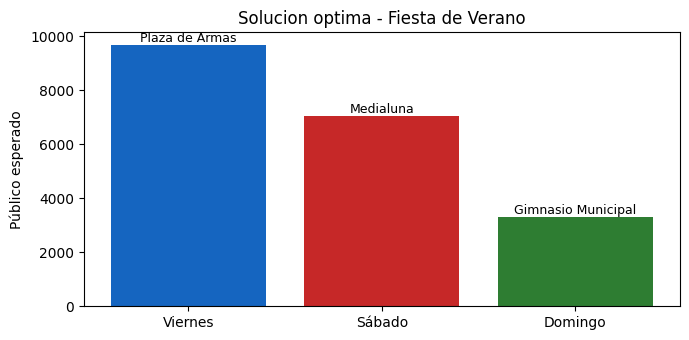

In [ ]:
# -------------------------------------------------------------------------
# LIBRERÍAS
# -------------------------------------------------------------------------

#Se importan librerías requeridas

# De esta librería, se utilizará la función "combinations", lo cual permitirá generar todas las combinaciones posibles de elementos de un conjunto.
# En este caso, como existen 15 artistas disponibles se formaran todas las combinaciones posibles de exactamente 3 artistas.
# Esto corresponde al conjunto c.
# Teóricamente, "combinations" debería generar 455 combinaciones posibles, sin considerar orden ni repeticiones de artistas dentro de cada combinación.
from itertools import combinations



# La librería gurobipy permitirá crear y resolver los modelos de optimización
# Dentro de esta misma librería, la función "GRB" proporciona constantes utilizadas por Gurobi, como "GRB.BINARY", "GRB.MAXIMIZE", "GRB.MINIMIZE".
import gurobipy as gp
from gurobipy import GRB


# -------------------------------------------------------------------------
# 1. Definición de Conjuntos y parametros precalculados
# -------------------------------------------------------------------------

A = list(ARTISTAS)            # Crea la lista con los nombres de los 15 artistas
N = NOCHES
R = list(RECINTOS)            # Lista de los recintos.
C = list(combinations(A, 3))  # Generación de las 455 combinaciones; C[k] es una combinación
K = range(len(C))            # Conjunto auxiliar para la creación para los índices de las combinaciones para Gurobi, así se puede identificar cada combinación con un número.
M = 16000                    # Valor para Big_M, siendo este el máximo de personas en 3 noches (de la totalidad del festival) (36000) - umbral (20000)


# -------------------------------------------------------------------------
# Cálculo del parámetro P_{c,n,r}
# -------------------------------------------------------------------------

P = {
    (k, n, r): round(min(FACTOR_NOCHE[n] * demanda(C[k]),
                         RECINTOS[r]['capacidad']))
    for k in K for n in N for r in R
}
# Esto permitirá entregar el público esperado




# -------------------------------------------------------------------------
# 2. Variables
# -------------------------------------------------------------------------

model = gp.Model('Fiesta_de_Verano') # Creación del modelo de optimización, con nombre "Fiesta de Verano"


#Creación de la variable X_{c,n,r}
X = {(k, n, r): model.addVar(vtype=GRB.BINARY, name=f'X_{k}_{i}_{j}')
     for k in K for i, n in enumerate(N) for j, r in enumerate(R)}

#Para entender el código:
#       mode.addVar() crea la variable de decisión
#       vtype=GRB.BINARY indica que puede tomar solamente los valores 0 o 1
#       name=...: Asigna un nombre a la variable para identificarla


#Creación de la variable Y_a
Y = {a: model.addVar(vtype=GRB.BINARY, name=f'Y_{i+1}')
     for i, a in enumerate(A)}

#Creación de la variable S
S = model.addVar(vtype=GRB.BINARY, name='S')

#Creación del público total en el festival
#   Esta definición corresponde a toda la expresión que está en la función objetivo (La sumatoria triple de P_{c,n,r} * X_{c,n,r})
publico_total = gp.quicksum(P[k, n, r] * X[k, n, r]
                           for k in K for n in N for r in R)

#       gp.quicksum() es la función que permite construir sumatorias.


# Costo de contratación de los artistas, si es que efectivamente fueron contratados.
#       Es la sumatoria de cada uno de los costos de cada artista con la variable Y_a
costo_artistas = gp.quicksum(ARTISTAS[a]['costo'] * Y[a] for a in A)


#Costo de los arriendos de los recintos
#       Es la sumatoria de X_{c,n,r} con el costo del recinto asociado
costo_recintos = gp.quicksum(RECINTOS[r]['costo'] * X[k, n, r]
                             for k in K for n in N for r in R)


# Costo total del festival
#       Se incluyen los dos costos calculados y también el costo de seguridad.
costo_total = costo_artistas + costo_recintos + COSTO_SEGURIDAD * S

# -------------------------------------------------------------------------
# 3. Restricciones
# -------------------------------------------------------------------------

# La función ".addConstr()" permite agregar una restricción al modelo de optimización.


# RESTRICCIÓN 1: Asignación única
#   Cada noche debe tener exactamente una combinación de artistas y un recinto asociado.
for i, n in enumerate(N):
    model.addConstr(gp.quicksum(X[k, n, r] for k in K for r in R) == 1,
                    name=f'una_terna_{i+1}')


# RESTRICCIÓN 2:
#   Un artista es contratado si alguna combinación de artistas que lo incluye efectivamente es elegida
for i, a in enumerate(A):
    model.addConstr(
        Y[a] == gp.quicksum(X[k, n, r]
                            for k in K if a in C[k] for n in N for r in R),
        name=f'contratacion_{i+1}',
    )

# RESTRICCIÓN 3 y 4:
# Un artista puede presentarse solo en las noches que está disponible.
for i, a in enumerate(A):
    for j, n in enumerate(N):
        disponible = int(n in ARTISTAS[a]['noches'])
        model.addConstr(
            gp.quicksum(X[k, n, r] for k in K if a in C[k] for r in R)
            <= disponible,
            name=f'disponibilidad_{i+1}_{j+1}',
        )

# RESTRICCIÓN 5:
# Si se contrata a La Sonora Copihue, Banda Fogata debe presentarse la misma noche.
sonora = 'La Sonora Copihue'
fogata = 'Banda Fogata'
for i, n in enumerate(N):
    model.addConstr(
        gp.quicksum(X[k, n, r] for k in K if sonora in C[k] for r in R)
        <= gp.quicksum(X[k, n, r] for k in K if fogata in C[k] for r in R),
        name=f'telonero_{i+1}',
    )

# RESTRICCIÓN 6
# La Nena Real y Yisus Beat no aceptan participar en el mismo festival
model.addConstr(Y['La Nena Real'] + Y['Yisus Beat'] <= 1,
                name='exclusion')

# RESTRICCIÓN 7 Y 8
# Si el público total esperado del festival supera las 20 000 personas, la municipalidad debe implementar un plan de seguridad.
model.addConstr(publico_total - UMBRAL_SEGURIDAD <= M * S,
                name='seguridad_obligatoria')
model.addConstr(publico_total >= (UMBRAL_SEGURIDAD + 1) * S,
                name='seguridad_solo_si_corresponde')

# RESTRICCIÓN 9
# El presupuesto para el evento es de 250 MM$ (el costo total debe ser menor o igual a este monto)
model.addConstr(costo_total <= PRESUPUESTO, name='presupuesto')


# -------------------------------------------------------------------------
# 4. Generar la primera optimizacion: MAXIMIZAR el público esperado (1*)
# -------------------------------------------------------------------------

# Se establece el parámetro MIPGap en 0, tal y como pide el enunciado
model.Params.MIPGap = 0

# Se establece la función objetivo del modelo, lo que queremos optimizar.
model.setObjective(publico_total, GRB.MAXIMIZE)

# Se ejecuta la optimización
model.optimize()

# Se chequea si es que efectivamente se consiguió demostrar la optimalidad.
if model.Status != GRB.OPTIMAL:
    raise RuntimeError('No se demostro optimalidad en la primera etapa.')


# Se obtiene el valor de la función objetivo de la solución encontrada, en este caso, el valor es el público máximo obtenido.
mejor_publico = round(model.ObjVal)
print(f'\nPublico maximo demostrado: {mejor_publico:,} personas')


# Se encontraron múltiples soluciones que permiten obtener 19 999 personas
# Por lo tanto, se tendrá que realizar una segunda optimización considerando también minimizar el costo, manteniendo el público máximo.


# -------------------------------------------------------------------------
# 5. Segunda optimización: Entre los óptimos, se tendrá que MINIMIZAR el costo
# -------------------------------------------------------------------------

# Se fija una nueva restricción que busca fijar el público máximo encontrado, buscando ahora minimizar el costo.
model.addConstr(publico_total == mejor_publico, name='fijar_publico_optimo')

# Se cambia la función objetivo, ahora buscando minimizar el costo total
model.setObjective(costo_total, GRB.MINIMIZE)

# Se ejecuta la optimización
model.optimize()

# Se chequea si se realizó la optimización
if model.Status != GRB.OPTIMAL:
    raise RuntimeError('No se demostro optimalidad en la segunda etapa.')

# -------------------------------------------------------------------------
# 6. Mostrar la solución y comprobar.
# -------------------------------------------------------------------------
parrilla = []
for n in N:
    for k in K:
        for r in R:
            if X[k, n, r].X > 0.5:
                parrilla.append((n, r, list(C[k])))
                break

print('\nRESULTADOS DE LA PREGUNTA (b)')
for n, r, artistas in parrilla:
    p = round(min(FACTOR_NOCHE[n] * demanda(artistas),
                  RECINTOS[r]['capacidad']))
    arriendo = RECINTOS[r]['costo']
    contrataciones = sum(ARTISTAS[a]['costo'] for a in artistas)
    print(f'{n}: {", ".join(artistas)} | {r} | publico {p:,} '
          f'| costo {arriendo + contrataciones} MM$')

print(f'Publico total: {round(publico_total.getValue()):,} personas')
print(f'Plan de seguridad: {"SI" if S.X > 0.5 else "NO"}')
print(f'Costo artistas: {costo_artistas.getValue():.0f} MM$')
print(f'Costo recintos: {costo_recintos.getValue():.0f} MM$')
print(f'Costo seguridad: {COSTO_SEGURIDAD * round(S.X)} MM$')
print(f'Costo total minimo: {costo_total.getValue():.0f} MM$')

# Visualizacion opcional, proporcionada por el archivo de datos.
mostrar_parrilla(parrilla, titulo='Solucion optima - Fiesta de Verano')

Para resolver el modelo, se realizó un código de programación lineal entera en python usando el *Solver* Gurobi.\
Se utilizó la misma metodología mencionada en el item *a)* en el cual se generan todas las combinaciones posibles y su público esperado, previo a la optimización.\
Así, posterior a aquello se tuvieron que realizar dos optimizaciones para encontrar la solución óptima y su respectivo valor.

Primeramente, se maximizó el público total esperado para el festival, sin embargo existían múltiples combinaciones que permitían obtener esto. Por lo cual, en segundo lugar se realizó otra optimización que, manteniendo el público total óptimo encontrado, minimiza el costo total del festival.

Como resultado de la segunda optmización, se obtuvo la siguiente solución:
* Para la primera noche (Viernes), se presentan Kevo Flow,  Los Cumbiancheros del Ñuble y Las Hermanas Quintral en Plaza de Armas, con un público esperado de $9 \ 657 $ personas.
* Para la segunda noche (Sábado), se presentan Camila Arrebol, Grupo Tierra Sur y  Niebla Austral en el recinto Medialuna, con un público esperado de $ 7 \ 045 $ personas.
* Para la tercera noche (Domigo), se presentan Ruta Cinco, Banda Fogata y Tomás del Lago en el Gimnasio Municipal, con un público esperado de $ 3 \ 297 $ personas.
* Así, el público total esperado es de $19 \ 999 $ personas, con un costo total de $249$ [MM\$] (estando dentro del presupuesto dado).
* Dado que el público no supera las $20 \ 000$ personas, **NO** fue necesario contratar el plan de seguridad.




# Item *c)*

***Enunciado:***

*El año pasado, la artista principal del sábado canceló su presentación a última hora y el público de esa noche cayó a menos de un tercio de lo esperado. La municipalidad quiere evitar que algo así vuelva a ocurrir.*



## *Pregunta I.*

***Pregunta I.***

*Para cada noche de su solución, determine cuánto público se esperaría si cancela cada uno de los tres artistas y se presentan solo los otros dos. Identifique qué noches dependen más de un solo artista.*


**Declaración de IA* : Para la realización de este código se utilizó Gemini.

In [ ]:
import itertools

# Parrilla base obtenida de la solución óptima del inciso (b)
parrilla_base = [
    ('Viernes', 'Plaza de Armas', ['Kevo Flow', 'Los Cumbiancheros del Ñuble', 'Las Hermanas Quintral']),
    ('Sábado', 'Medialuna', ['Camila Arrebol', 'Grupo Tierra Sur', 'Niebla Austral']),
    ('Domingo', 'Gimnasio Municipal', ['Ruta Cinco', 'Banda Fogata', 'Tomás del Lago'])
]

print("=" * 90)
print(f"{'NOCHE':<10} | {'ARTISTA CANCELADO':<28} | {'ARTISTAS RESTANTES':<45} | {'PÚBLICO ESPERADO'}")
print("-" * 90)

for noche, recinto, artistas_noche in parrilla_base:
    # Calculamos el público original de referencia para esta noche
    demanda_orig = demanda(artistas_noche)
    pub_original = round(min(FACTOR_NOCHE[noche] * demanda_orig, RECINTOS[recinto]['capacidad']))

    # Simulamos la cancelación de cada uno de los 3 artistas uno por uno
    for artista_a_cancelar in artistas_noche:
        # Creamos la combinación de los 2 artistas restantes
        artistas_dos = [a for a in artistas_noche if a != artista_a_cancelar]

        # Recalculamos la demanda y el público con solo 2 artistas
        demanda_dos = demanda(artistas_dos)
        pub_esperado = round(min(FACTOR_NOCHE[noche] * demanda_dos, RECINTOS[recinto]['capacidad']))

        # Diferencia respecto al original
        perdida = pub_original - pub_esperado

        restantes_str = ", ".join(artistas_dos)
        print(f"{noche:<10} | {artista_a_cancelar:<28} | {restantes_str:<45} | {pub_esperado:,d} personas ( Pierde: -{perdida:,d} )")

    print("-" * 90)

NOCHE      | ARTISTA CANCELADO            | ARTISTAS RESTANTES                            | PÚBLICO ESPERADO
------------------------------------------------------------------------------------------
Viernes    | Kevo Flow                    | Los Cumbiancheros del Ñuble, Las Hermanas Quintral | 3,502 personas ( Pierde: -6,155 )
Viernes    | Los Cumbiancheros del Ñuble  | Kevo Flow, Las Hermanas Quintral              | 6,741 personas ( Pierde: -2,916 )
Viernes    | Las Hermanas Quintral        | Kevo Flow, Los Cumbiancheros del Ñuble        | 7,390 personas ( Pierde: -2,267 )
------------------------------------------------------------------------------------------
Sábado     | Camila Arrebol               | Grupo Tierra Sur, Niebla Austral              | 1,986 personas ( Pierde: -5,059 )
Sábado     | Grupo Tierra Sur             | Camila Arrebol, Niebla Austral                | 5,395 personas ( Pierde: -1,650 )
Sábado     | Niebla Austral               | Camila Arrebol, Grupo Tierra S

Con el código presente, se calculó cuánto público asistiría si uno de los tres artistas de una noche cancela, presentando solamente los otros dos.\
En caso de que aquello ocurra, se tiene que volver a calcular la demanda, pero considerando solamente dos artistas, sin embargo, no es suficiente restar la demanda individual del artista que cancela, dado que también varían las interacciones e incluso el efecto arrastre.\
Como resultado se obtuvieron nueve escenarios distintos con respecto a qué artista cancelaba.

## *Pregunta II.*

***Pregunta II.*** \
A partir de su análisis, proponga una o más condiciones que hagan la parrilla menos dependiente de un solo artista. Incorpórelas al modelo, resuélvalo y compare las alternativas en términos de público y costo.

Para asegurarnos que el Festival no sufrirá las consecuencias frente a la cancelación de uno de los artistas, se hace un enfoque de optimizacion robusta, donde se anticipa el problema de alguno de los artistas. Con esto definimos el publico proyectado en el peor escenario para cada combinación de artistas $c \in C$ asignada en la noche $n$ al recinto $r$.

Sea $c \setminus \{a\}$ el subconjunto resultante tras la caída de cualquier artista $a \in c$. El público obtenido bajo dicha situación se calcula como:
$$P^{-a}_{c,n,r} = \text{round}\left( \min\left\{ \phi_n \cdot D(c \setminus \{a\}), K_r \right\} \right)$$
a partir de las posibles caídas, se determina el peor rendimiento posible  ($P^{\text{peor}}$) aplicando el mínimo al conjunto de artistas que componen el evento:
$$P^{\text{peor}}_{c,n,r} = \min_{a \in c} P^{-a}_{c,n,r}$$

A partir de esto se debe aplicar una restricción de garantía de robustez relativa, que evita que la estabilidad de la parrilla del festival dependa de un solo artista. Se aplica una cota de desempeño $\alpha$ para el valor mínimo que se espera que caíga la demanda del festival ante el peor rendimiento por la caída de un artista.   
La restricción exige que, ante la peor cancelación posible, cada noche del festival conserve al menos una fracción $\alpha$ de su público esperado nominal:
$$\sum_{r \in R} \sum_{c \in C} P^{\text{peor}}_{c,n,r} X_{c,n,r} \ge \alpha \sum_{r \in R} \sum_{c \in C} P_{c,n,r} X_{c,n,r} \quad \forall n \in N$$



*Declaración de IA: Para la realización de este código se utilizó Gemini.

Set parameter MIPGap to value 0
Gurobi Optimizer version 14.0.0 build v14.0.0rc1 (linux64 - "Ubuntu 24.04.5 LTS")

CPU model: Intel(R) Xeon(R) CPU @ 2.20GHz, instruction set [SSE2|AVX|AVX2]
Thread count: 1 physical cores, 2 logical processors, using up to 2 threads

Non-default parameters:
MIPGap  0

Academic license 2884705 - for non-commercial use only - registered to fr___@alumnos.uai.cl
Optimize a model with 88 rows, 4111 columns and 46499 nonzeros (Max)
Model fingerprint: 0x35845c50
Model has 4095 linear objective coefficients
Variable types: 0 continuous, 4111 integer (4111 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+04]
  Objective range  [1e+03, 1e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 2e+04]

Found heuristic solution: objective 10599.000000
Presolve removed 66 rows and 3174 columns
Presolve time: 0.06s
Presolved: 22 rows, 937 columns, 5802 nonzeros
Variable types: 0 continuous, 937 integer (937 binary)

Root relaxation: objective 1.

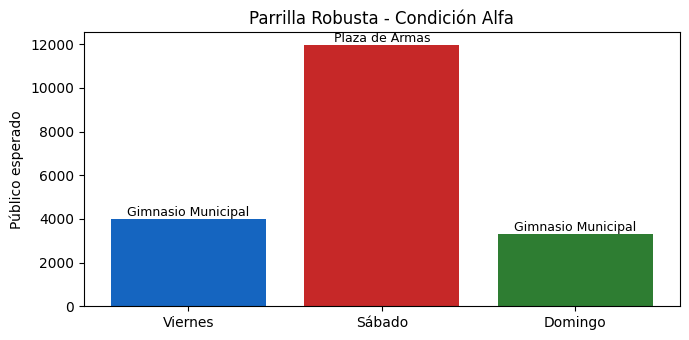


Público nominal total obtenido: 19,265 personas
¿Se requiere plan de seguridad?: No
Costo total utilizado: 250.0 MM$ (Presupuesto máx: 250 MM$)


In [ ]:
import gurobipy as gp
from gurobipy import GRB
import itertools

# =============================================================================
# 1. PARÁMETRO DE ROBUSTEZ (Condición A)
# =============================================================================
# Alfa (alpha): Fracción mínima de público que cada noche debe conservar
# ante la peor cancelación posible (ej: 1/3 para evitar la caída del año pasado)
ALPHA = 1/2

# =============================================================================
# 2. PRE-CÁLCULO DE PÚBLICO NOMINAL (P) Y PEOR CASO (P_peor)
# =============================================================================
combinaciones = list(itertools.combinations(ARTISTAS.keys(), 3))

P = {}          # Público nominal normal P_{c,n,r}
P_peor = {}     # Público en el peor escenario de cancelación P^{peor}_{c,n,r}

for c in combinaciones:
    for n in NOCHES:
        for r in RECINTOS.keys():
            # 1. Público nominal de la combinación completa
            dem_nominal = demanda(c)
            P[(c, n, r)] = round(min(FACTOR_NOCHE[n] * dem_nominal, RECINTOS[r]['capacidad']))

            # 2. Cálculo del peor caso de cancelación (P_peor)
            # Evaluamos la demanda si se cae individualmente cada uno de los 3 artistas
            publicos_contingencia = []
            for artista_a in c:
                # Subconjunto c \ {a} (los 2 artistas restantes)
                c_sin_a = [x for x in c if x != artista_a]
                dem_sin_a = demanda(c_sin_a)
                pub_sin_a = round(min(FACTOR_NOCHE[n] * dem_sin_a, RECINTOS[r]['capacidad']))
                publicos_contingencia.append(pub_sin_a)

            # El peor caso es el mínimo público resultante entre las 3 posibles bajas
            P_peor[(c, n, r)] = min(publicos_contingencia)

# =============================================================================
# 3. CREACIÓN DEL MODELO Y VARIABLES
# =============================================================================
m = gp.Model("Festival_Peumayen_Robusto_PeorCaso")
m.Params.MIPGap = 0  # Optimalidad exacta

llaves_X = [(c, n, r) for c in combinaciones for n in NOCHES for r in RECINTOS.keys()]

# Variable X_{c,n,r}: 1 si se asigna la combinación c en la noche n al recinto r
X = m.addVars(llaves_X, vtype=GRB.BINARY, name="X")

# Variable Y_a: 1 si el artista a es contratado
Y = m.addVars(ARTISTAS.keys(), vtype=GRB.BINARY, name="Y")

# Variable S: 1 si se activa el plan de seguridad
S = m.addVar(vtype=GRB.BINARY, name="Seguridad")

# =============================================================================
# 4. RESTRICCIONES DEL MODELO
# =============================================================================
# 1. Asignación única por noche
m.addConstrs((gp.quicksum(X[c, n, r] for c in combinaciones for r in RECINTOS.keys()) == 1
              for n in NOCHES), name="Asignacion_unica")

# 2. Definición de contratación Y_a
for a in ARTISTAS.keys():
    m.addConstr(Y[a] == gp.quicksum(X[c, n, r]
                                    for c in combinaciones if a in c
                                    for n in NOCHES
                                    for r in RECINTOS.keys()),
                name=f"Contrata_{a}")

# 3. Un artista se presenta a lo más una vez
m.addConstrs((Y[a] <= 1 for a in ARTISTAS.keys()), name="Max_una_vez")

# 4. Disponibilidad en la noche
for a in ARTISTAS.keys():
    for n in NOCHES:
        disp = 1 if n in ARTISTAS[a]['noches'] else 0
        m.addConstr(gp.quicksum(X[c, n, r]
                                for c in combinaciones if a in c
                                for r in RECINTOS.keys()) <= disp,
                    name=f"Disp_{a}_{n}")

# 5. Teloneros: Si va Sonora Copihue, debe ir Banda Fogata la misma noche
m.addConstrs((gp.quicksum(X[c, n, r] for c in combinaciones if 'La Sonora Copihue' in c for r in RECINTOS.keys()) <=
              gp.quicksum(X[c, n, r] for c in combinaciones if 'Banda Fogata' in c for r in RECINTOS.keys())
              for n in NOCHES), name="Teloneros")

# 6. Exclusión: Nena Real y Yisus Beat no pueden coincidir
m.addConstr(Y['La Nena Real'] + Y['Yisus Beat'] <= 1, name="Exclusion")

# 7. Plan de seguridad basado en el público nominal total
publico_total_nominal = gp.quicksum(P[(c, n, r)] * X[c, n, r] for c in combinaciones for n in NOCHES for r in RECINTOS.keys())
M = 16000
m.addConstr(publico_total_nominal - UMBRAL_SEGURIDAD <= M * S, name="Activa_Seguridad")
m.addConstr(publico_total_nominal >= 20001 * S, name="Desactiva_Seguridad_Innecesaria")

# 8. Presupuesto (250 MM$)
costo_artistas = gp.quicksum(ARTISTAS[a]['costo'] * Y[a] for a in ARTISTAS.keys())
costo_recintos = gp.quicksum(RECINTOS[r]['costo'] * X[c, n, r] for c in combinaciones for n in NOCHES for r in RECINTOS.keys())
costo_seguridad_total = COSTO_SEGURIDAD * S
costo_total = costo_artistas + costo_recintos + costo_seguridad_total

m.addConstr(costo_total <= PRESUPUESTO, name="Presupuesto")

# =============================================================================
# 9. NUEVA RESTRICCIÓN DE ROBUSTEZ: CONDICIÓN A (Público peor vs Alfa * Público nominal)
# =============================================================================
m.addConstrs((
    gp.quicksum((P_peor[(c, n, r)] - ALPHA * P[(c, n, r)]) * X[c, n, r]
                for c in combinaciones for r in RECINTOS.keys()) >= 0
    for n in NOCHES
), name="Robustez_PeorCaso_Alfa")

# =============================================================================
# 10. RESOLUCIÓN FASE 1: MAXIMIZAR PÚBLICO NOMINAL
# =============================================================================
m.setObjective(publico_total_nominal, GRB.MAXIMIZE)
m.optimize()

max_publico_robusto = m.ObjVal

# =============================================================================
# 11. RESOLUCIÓN FASE 2: MINIMIZAR COSTO (Desempate)
# =============================================================================
m.addConstr(publico_total_nominal == max_publico_robusto, name="Fijar_Publico_Optimo")
m.setObjective(costo_total, GRB.MINIMIZE)
m.optimize()

# =============================================================================
# 12. REPORTE DE RESULTADOS
# =============================================================================
if m.SolCount > 0:
    parrilla_optima_robusta = []
    for c in combinaciones:
        for n in NOCHES:
            for r in RECINTOS.keys():
                if X[c, n, r].X > 0.5:
                    parrilla_optima_robusta.append((n, r, list(c)))

    print("\n" + "="*70)
    print("--- RESULTADOS ÓPTIMOS CON OPTIMIZACIÓN ROBUSTA (PEOR CASO) ---")
    print("="*70)
    mostrar_parrilla(parrilla_optima_robusta, titulo="Parrilla Robusta - Condición Alfa")

    print(f"\nPúblico nominal total obtenido: {publico_total_nominal.getValue():,.0f} personas")
    print(f"¿Se requiere plan de seguridad?: {'Sí' if S.X > 0.5 else 'No'}")
    print(f"Costo total utilizado: {costo_total.getValue()} MM$ (Presupuesto máx: {PRESUPUESTO} MM$)")
else:
    print("No se encontró solución factible con el nivel de alfa seleccionado.")

In [ ]:
# =============================================================================
# SIMULACIÓN DE CANCELACIONES PARA LA NUEVA PARRILLA ROBUSTA (PREGUNTA 1 / INCISO C.1)
# =============================================================================
import itertools

# NOTA: Asegúrate de haber ejecutado previamente el bloque de optimización robusta
# para que 'parrilla_optima_robusta' esté definida en tu entorno.
# Si deseas probarlo directamente, asegúrate de que la variable contenga la solución, por ejemplo:
# parrilla_optima_robusta = [
#     ('Viernes', 'Recinto_Asignado', ['Artista1', 'Artista2', 'Artista3']),
#     ('Sábado', 'Recinto_Asignado', ['Artista1', 'Artista2', 'Artista3']),
#     ('Domingo', 'Recinto_Asignado', ['Artista1', 'Artista2', 'Artista3'])
# ]

print("=" * 115)
print(f"{'NOCHE':<10} | {'RECINTO':<20} | {'ARTISTA CANCELADO':<28} | {'ARTISTAS RESTANTES':<35} | {'PÚBLICO ESPERADO':<16} | {'DIFERENCIA'}")
print("-" * 115)

for noche, recinto, artistas_noche in parrilla_optima_robusta:
    # 1. Cálculo del público nominal de referencia para la noche robusta
    demanda_orig = demanda(artistas_noche)
    pub_original = round(min(FACTOR_NOCHE[noche] * demanda_orig, RECINTOS[recinto]['capacidad']))

    # 2. Iteración para simular la baja de cada artista de manera individual
    for artista_a_cancelar in artistas_noche:
        # Subconjunto con los 2 artistas restantes
        artistas_dos = [a for a in artistas_noche if a != artista_a_cancelar]

        # 3. Recálculo aplicando la función de demanda y aforo del recinto
        demanda_dos = demanda(artistas_dos)
        pub_esperado = round(min(FACTOR_NOCHE[noche] * demanda_dos, RECINTOS[recinto]['capacidad']))

        # 4. Cuantificación de la pérdida de público
        perdida = pub_original - pub_esperado

        restantes_str = ", ".join(artistas_dos)
        print(f"{noche:<10} | {recinto:<20} | {artista_a_cancelar:<28} | {restantes_str:<35} | {pub_esperado:6,d} personas   |  -{perdida:,d}")

    print("-" * 115)

NOCHE      | RECINTO              | ARTISTA CANCELADO            | ARTISTAS RESTANTES                  | PÚBLICO ESPERADO | DIFERENCIA
-------------------------------------------------------------------------------------------------------------------
Sábado     | Plaza de Armas       | Camila Arrebol               | Kevo Flow, Los Cumbiancheros del Ñuble |  8,211 personas   |  -3,741
Sábado     | Plaza de Armas       | Kevo Flow                    | Camila Arrebol, Los Cumbiancheros del Ñuble |  6,898 personas   |  -5,054
Sábado     | Plaza de Armas       | Los Cumbiancheros del Ñuble  | Camila Arrebol, Kevo Flow           |  8,835 personas   |  -3,117
-------------------------------------------------------------------------------------------------------------------
Domingo    | Gimnasio Municipal   | Grupo Tierra Sur             | Las Hermanas Quintral, Niebla Austral |  2,164 personas   |  -1,169
Domingo    | Gimnasio Municipal   | Las Hermanas Quintral        | Grupo Tierra Sur, Nie

## *Pregunta III.*

***Pregunta III.*** \
Proponga una o más condiciones que permitan mejorar la situación de la noche más desmejorada sin aumentar el presupuesto de 250 MM$. Incorpórelas al modelo, resúelvalo y compare sus efectos sobre el público de cada noche y el público total.

Al revisar los resultados el modelo concentra a los mejores artistas en las dos noches de mayor arrastre dejando la tercera noche con un factor mas bajo. Para arreglar esto sin aumentar el presupuesto debemos utilizar una condicion de equidad para balancear las noches.

# Item *d)*